# Инструкция, выбор токенов и ответ по документу

Перед нами один документ о продлении книг. В нём есть срок и исключение, но нет числа продлений за семестр. Сначала сами определим ответы на три вопроса, затем сравним две инструкции для модели. Отдельные опыты покажут влияние декодирования и соблюдение JSON-формата.

In [1]:
from pathlib import Path
import os
import json
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Находим корень раздачи независимо от места запуска Jupyter.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "requests.csv").exists())
DATA = ROOT / "data"
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
np.random.seed(42)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.figsize": (8, 4)})


## Читаем источник

Загрузим модель из подготовленного комплекта и откроем D03. Найдите в нём срок, условие чужой брони и сведения о числе продлений за семестр. Для последнего вопроса важно проверить именно наличие факта.

До вызова модели запишите ожидаемые ответы. Инструкция по подготовке файлов находится в START; в работе используется один и тот же источник и фиксированные веса.

In [2]:
import math
import time
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed

torch.set_num_threads(4)
MODEL_ROOT = Path(os.environ.get("NLP_MODELS_DIR", ROOT / ".cache" / "models"))
MODEL_DIR = MODEL_ROOT / "generator"
if not (MODEL_DIR / "config.json").exists():
    raise FileNotFoundError("Сначала выполните scripts/prepare_models.py при доступном интернете")
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR, local_files_only=True)
model, loading_info = AutoModelForCausalLM.from_pretrained(MODEL_DIR, local_files_only=True,
    dtype=torch.float32, output_loading_info=True)
if loading_info["missing_keys"] or loading_info["mismatched_keys"] or loading_info["error_msgs"]:
    raise RuntimeError("Не удалось полностью загрузить веса генератора")
model.eval(); model.requires_grad_(False)
assert next(model.parameters()).device.type == "cpu"
MAX_INPUT, MAX_NEW = 768, 64
documents = pd.read_csv(DATA / "knowledge.csv", keep_default_na=False)
document = documents.loc[documents["doc_id"].eq("D03"), "text"].iloc[0]
questions = {
    "duration": "На сколько дней можно продлить книгу?",
    "reservation": "Можно ли продлить книгу, если её забронировал другой читатель?",
    "count": "Сколько раз за семестр можно продлевать книгу?",
}
print(document)


D:\AIS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights:  39%|███▊      | 120/311 [00:00<00:00, 1199.72it/s]

Loading weights:  77%|███████▋  | 240/311 [00:00<00:00, 1178.25it/s]

Loading weights: 100%|██████████| 311/311 [00:00<00:00, 1201.93it/s]

В библиотеке учебного университета «Север» книгу можно продлить на 14 дней через кабинет читателя. Продление недоступно, если на издание оформлена бронь другого читателя. Тогда книгу нужно вернуть к указанной дате. Срок продления учебный и не относится к реальному вузу.


### Один шаг выбора на числах

Для оценок (2;1;0) сначала вычислим обычный устойчивый softmax. Прибавьте к трём оценкам одно большое число и проверьте, изменились ли вероятности. Затем в задании добавим температуру и отбор кандидатов.

In [3]:
demo_logits = np.array([2., 1., 0.])
demo_exp = np.exp(demo_logits - demo_logits.max())
print(demo_exp / demo_exp.sum())

[0.66524096 0.24472847 0.09003057]


## 1. Temperature и top-p

Напишите `temperature_probs(logits, T)` с T>0: поделите оценки на T и примените устойчивый softmax. При недопустимой температуре вызывайте `ValueError`. Создайте DataFrame `temperature_table` для оценок (2;1;0): индекс — 0.5, 1, 2; колонки — `token_A`, `token_B`, `token_C`.

Затем напишите `nucleus(probabilities, p)` для 0<p≤1. Верните массив исходной длины, оставив минимальный набор верхних вероятностей с суммой не меньше p. Остальные занулите, оставшиеся нормируйте. При неверных параметрах или ненормированном входе вызывайте `ValueError`.

Проверьте (0,5;0,3;0,2) при p=0,75. Что изменилось после исключения третьего токена? Почему greedy нельзя реализовать делением на T=0?

,token_A,token_B,token_C
0.5,0.866813,0.117310,0.015876
1.0,0.665241,0.244728,0.090031
2.0,0.506480,0.307196,0.186324


Nucleus: [0.625 0.375 0.   ]


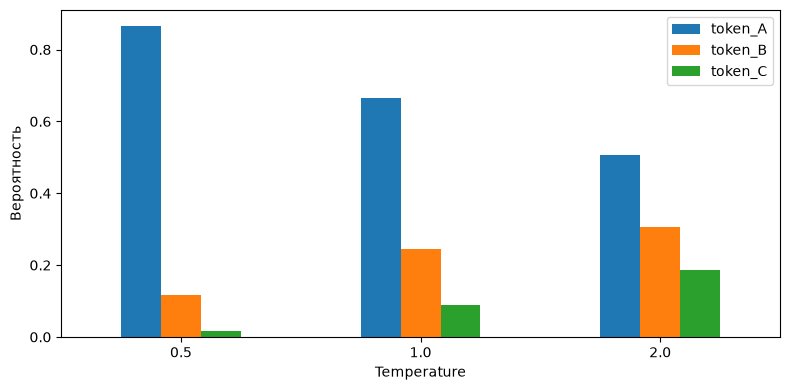

In [4]:
def temperature_probs(logits, T):
    if T <= 0:
        raise ValueError("T должна быть положительной")
    z = np.asarray(logits, dtype=float) / T
    e = np.exp(z - z.max())
    return e / e.sum()

def nucleus(probabilities, p):
    probabilities = np.asarray(probabilities, dtype=float)
    if not 0 < p <= 1 or probabilities.ndim != 1 or not len(probabilities):
        raise ValueError("Проверьте p и форму вероятностей")
    if (probabilities < 0).any() or not np.isclose(probabilities.sum(), 1):
        raise ValueError("Нужны неотрицательные нормированные вероятности")
    order = np.argsort(-probabilities, kind="stable")
    count = min(len(order), np.searchsorted(np.cumsum(probabilities[order]), p, side="left") + 1)
    out = np.zeros_like(probabilities)
    out[order[:count]] = probabilities[order[:count]]
    return out / out.sum()

temperature_table = pd.DataFrame([temperature_probs([2,1,0], T) for T in [0.5,1,2]],
                                 index=[0.5,1,2], columns=["token_A","token_B","token_C"])
display(temperature_table)
print("Nucleus:", nucleus([0.5,0.3,0.2], 0.75))
temperature_table.plot.bar(rot=0); plt.ylabel("Вероятность"); plt.xlabel("Temperature"); plt.tight_layout(); plt.show()

In [5]:
assert np.allclose(temperature_table.sum(axis=1), 1)
assert np.allclose(temperature_probs([2,1,0],1), [0.66524096,0.24472847,0.09003057])
assert np.allclose(nucleus([0.5,0.3,0.2],.75), [.625,.375,0])
try:
    temperature_probs([1,2],0)
except ValueError:
    pass
else:
    raise AssertionError("Greedy не реализуется делением на T=0")

При T=1 получаются примерно (0,665241;0,244728;0,090031). Для nucleus остаются первые два кандидата с массой 0,8; после нормировки это (0,625;0,375;0). В реальной генерации дополнительно применяется top_k=20.

### Как сообщения превращаются во вход

Ниже небольшой пример штатного шаблона Qwen3. Он не вызывает генерацию: посмотрите, где находятся роли и начало ответа. Эту последовательность нужно сохранить в функции подготовки.

In [6]:
demo_messages = [{"role": "system", "content": "Ты учебный помощник. Отвечай по-русски"},
                 {"role": "user", "content": "Что такое токен?"}]
demo_rendered = tokenizer.apply_chat_template(demo_messages, tokenize=False,
                                              add_generation_prompt=True, enable_thinking=False)
print(demo_rendered)

<|im_start|>system
Ты учебный помощник. Отвечай по-русски<|im_end|>
<|im_start|>user
Что такое токен?<|im_end|>
<|im_start|>assistant
<think>

</think>




## 2. Подготовка входа

Закончите `prepare_input(user_text)`, возвращающую `(batch, input_length)`. Используйте такое же system-сообщение и параметры шаблона, как в рабочем примере. Второе сообщение имеет роль user и содержит переданный текст.

Полученную строку токенизируйте с `add_special_tokens=False`, `return_tensors="pt"`, без усечения. Для пустого или нестрокового входа, а также длины больше `MAX_INPUT`, вызывайте `ValueError`.

Выведите декодированный вход для короткого вопроса. Почему длину нужно проверять после шаблона, а добавление специальных токенов второй раз изменило бы запрос?

In [7]:
def prepare_input(user_text):
    if not isinstance(user_text, str) or not user_text.strip():
        raise ValueError("Нужен непустой пользовательский текст")
    messages = [{"role":"system", "content":"Ты учебный помощник. Отвечай по-русски"},
                {"role":"user", "content":user_text}]
    rendered = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    batch = tokenizer(rendered, add_special_tokens=False, return_tensors="pt")
    length = int(batch["input_ids"].shape[1])
    if length > MAX_INPUT:
        raise ValueError(f"Вход длиной {length} токенов превышает предел {MAX_INPUT}")
    return batch, length

batch_example, length_example = prepare_input("Коротко объясни, что такое токен.")
print("Входных токенов:", length_example)
print(tokenizer.decode(batch_example["input_ids"][0]))

Входных токенов: 45
<|im_start|>system
Ты учебный помощник. Отвечай по-русски<|im_end|>
<|im_start|>user
Коротко объясни, что такое токен.<|im_end|>
<|im_start|>assistant
<think>

</think>




In [8]:
b, n = prepare_input("Короткий учебный вопрос")
assert b["input_ids"].shape == b["attention_mask"].shape and b["input_ids"].shape[1] == n
assert 0 < n <= MAX_INPUT
try:
    prepare_input("слово "*2000)
except ValueError:
    pass
else:
    raise AssertionError("Большой вход должен быть отклонён, не усечён молча")

Общее system-сообщение не ограничивает ответ документом: это отличие strict, которое будет исследоваться отдельно. Предел относится к реальному входу с ролями и разделителями. Слишком длинный источник не обрезается молча.

## Вызов генератора

Оболочка уже написана, чтобы основной опыт был посвящён ответам. Проследите в ней выделение новых токенов после `input_length`. Поля `text`, `prompt`, `input_tokens`, `new_tokens`, `stop` и параметры вызова понадобятся для сравнения и повторения опыта. Время хранится только среди технических сведений журнала.

In [9]:
# Готовая оболочка генерации сохраняет метаданные и выделяет только новые токены.
def generate_answer(user_text, mode="greedy", temperature=0.7, top_p=0.8, seed=42, max_new=64):
    if mode not in {"greedy","sample"} or not 1 <= max_new <= MAX_NEW:
        raise ValueError("Проверьте режим и лимит")
    if mode == "sample" and (temperature <= 0 or not 0 < top_p <= 1):
        raise ValueError("Некорректные параметры выборки")
    batch, length = prepare_input(user_text)
    if length + max_new > model.config.max_position_embeddings:
        raise ValueError("Превышено окно модели")
    kwargs = {"max_new_tokens":max_new, "do_sample":mode=="sample",
              "pad_token_id":tokenizer.eos_token_id, "use_cache":True}
    if mode == "sample":
        kwargs.update(temperature=temperature, top_p=top_p, top_k=20)
    set_seed(seed)
    started = time.perf_counter()
    with torch.inference_mode():
        output = model.generate(**batch, **kwargs)
    new_ids = output[0, length:]
    eos = model.generation_config.eos_token_id
    eos_ids = {eos} if isinstance(eos, int) else set(eos)
    stopped = "EOS" if len(new_ids) and int(new_ids[-1]) in eos_ids else ("limit" if len(new_ids)>=max_new else "other")
    return {"text":tokenizer.decode(new_ids, skip_special_tokens=True), "prompt":user_text,
            "input_tokens":length, "new_tokens":len(new_ids), "stop":stopped,
            "seconds":time.perf_counter()-started, "mode":mode,
            "temperature":temperature if mode=="sample" else None,
            "top_p":top_p if mode=="sample" else None, "top_k":20 if mode=="sample" else None, "seed":seed}


## 3. Две инструкции к одному источнику

Напишите `build_prompt(question, variant)`, где variant — basic или strict. Оба варианта содержат один `document` и переданный вопрос. Basic содержит только документ, вопрос и начало ответа. Strict добавляет: «Используй только документ ниже. Ответь одним коротким предложением. Если нужного факта нет, ответь точно: НЕТ ДАННЫХ».

Функция `generate_answer` возвращает исходный ответ и сведения о вызове. Выполните шесть greedy-запросов: каждый вариант инструкции для каждого вопроса из `questions`. Сохраните список `prompt_records`; каждая запись содержит `question_id`, `variant`, `question` и все поля `generate_answer`. Создайте `prompt_results = pd.DataFrame(prompt_records)`.

Сначала сохраните ответы без исправлений. Их оценка по документу будет в последнем разделе.

In [10]:
def build_prompt(question, variant):
    if variant not in {"basic","strict"}:
        raise ValueError("Неизвестный вариант")
    instruction = "" if variant == "basic" else (
        "Используй только документ ниже. Ответь одним коротким предложением. "
        "Если нужного факта нет, ответь точно: НЕТ ДАННЫХ.\n")
    return instruction + f"Документ:\n{document}\n Вопрос: {question}\n Ответ:"

prompt_records = []
for variant in ["basic","strict"]:
    for question_id, question in questions.items():
        result = generate_answer(build_prompt(question, variant), mode="greedy")
        prompt_records.append({"question_id":question_id, "variant":variant, "question":question, **result})
        print(variant, question_id, result["stop"], repr(result["text"]))
prompt_results = pd.DataFrame(prompt_records)
display(prompt_results[["variant","question_id","input_tokens","new_tokens","stop"]])

basic duration EOS 'На 14 дней.'


basic reservation EOS 'Да, можно продлить книгу, если её забронировал другой читатель.'


basic count limit 'Сколько раз за семестр можно продлевать книгу — это зависит от того, сколько раз книга была продлена в библиотеке. Если книга продлена на 14 дней, то за каждую неделю можно продлить её. Поэтому, если кни'


strict duration EOS 'На 14 дней.'


strict reservation EOS 'Ответ: Можно.'


strict count EOS 'Продление книги можно продлить на 14 дней.'


,variant,question_id,input_tokens,new_tokens,stop
0,basic,duration,147,7,EOS
1,basic,reservation,154,21,EOS
2,basic,count,151,64,limit
3,strict,duration,186,7,EOS
4,strict,reservation,193,6,EOS
5,strict,count,190,16,EOS


In [11]:
assert len(prompt_records) == 6
assert set(prompt_results["variant"]) == {"basic","strict"}
assert set(prompt_results["question_id"]) == set(questions)
assert prompt_results["mode"].eq("greedy").all()
assert prompt_results["input_tokens"].le(MAX_INPUT).all() and prompt_results["new_tokens"].between(1, MAX_NEW).all()

Эталонные ожидания: duration — 14 дней; reservation — нельзя при брони другого читателя; count — в документе нет числа продлений. Проверки кода подтверждают устройство эксперимента; факты оцениваются чтением результата.

## 4. Один запрос, разные выборки

Возьмите strict-промпт для `questions["duration"]`. Выполните sampling при T=0.5 и 1.0, для каждой температуры seed 7 и 42. top_p=0.8; top_k=20 уже задан в оболочке. Сохраните четыре результата в `decoding_records` и DataFrame `decoding_results`.

Сравните их с greedy-ответом того же запроса из `prompt_results`. Если все строки совпали, оставьте это наблюдение в выводе. Как оно соотносится с расчётом распределений в первом задании?

In [12]:
decoding_records = []
fixed_prompt = build_prompt(questions["duration"], "strict")
for T in [0.5,1.0]:
    for seed in [7,42]:
        result = generate_answer(fixed_prompt, mode="sample", temperature=T, top_p=.8, seed=seed)
        decoding_records.append(result)
        print("T", T,"seed", seed, result["stop"], repr(result["text"]))
decoding_results = pd.DataFrame(decoding_records)

T 0.5 seed 7 EOS '14 дней.'


T 0.5 seed 42 EOS '14 дней.'


T 1.0 seed 7 EOS '14 дней.'


T 1.0 seed 42 EOS '14 дней.'


In [13]:
assert len(decoding_records) == 4
assert set(zip(decoding_results["temperature"], decoding_results["seed"])) == {(0.5,7),(0.5,42),(1.0,7),(1.0,42)}
assert decoding_results["prompt"].nunique() == 1 and decoding_results["top_p"].eq(.8).all()

В проверенном запуске все четыре выборки дали «14 дней» и EOS. Изменение вероятностей не обязано проявиться в каждом конкретном коротком выводе. По четырём ответам нельзя установить общее превосходство настройки.

## 5. Проверяем JSON

Напишите `validate_json_answer(text)`. Результат — словарь с `valid` (bool), `error` (str) и `parsed` (dict либо None). Принимайте только JSON-объект с ровно двумя ключами: `answer` — строка, `has_answer` — логическое значение. Markdown-ограждения и дополнительные поля не входят в требуемый формат. Ошибка возвращается в словаре и не прерывает разбор.

Отправьте отдельный greedy-запрос о сроке продления по D03, потребовав этот JSON без дополнительных слов. Сохраните ответ в `json_record`, проверку — в `json_validation`.

Сначала проверьте структуру, затем сопоставьте значение с документом. Почему успешный парсинг ещё не подтверждает ответ?

In [14]:
def validate_json_answer(text):
    if not isinstance(text, str):
        return {"valid":False, "error":"Нужна строка", "parsed":None}
    try:
        obj = json.loads(text.strip())
    except (json.JSONDecodeError, TypeError) as e:
        return {"valid":False, "error":str(e), "parsed":None}
    if not isinstance(obj, dict) or set(obj) != {"answer","has_answer"}:
        return {"valid":False, "error":"Нужен объект с ровно answer и has_answer", "parsed":obj if isinstance(obj, dict) else None}
    if not isinstance(obj["answer"],str) or type(obj["has_answer"]) is not bool:
        return {"valid":False, "error":"Неверные типы", "parsed":obj}
    return {"valid":True, "error":"", "parsed":obj}

json_prompt = ("Ответь только по документу. Верни только JSON без Markdown, с ровно двумя полями: "
               "answer (строка), has_answer (логическое значение). "
               f"Документ: {document} Вопрос: {questions['duration']}")
json_record = generate_answer(json_prompt, mode="greedy")
json_validation = validate_json_answer(json_record["text"])
print("Исходный ответ:", repr(json_record["text"]), "Остановка:", json_record["stop"])
print(json_validation)

Исходный ответ: '{\n  "answer": "14",\n  "has_answer": true\n}' Остановка: EOS
{'valid': True, 'error': '', 'parsed': {'answer': '14', 'has_answer': True}}


In [15]:
assert validate_json_answer('{"answer":"14 дней","has_answer":true}')["valid"]
assert not validate_json_answer('{"answer":"нет","has_answer":"false"}')["valid"]
assert not validate_json_answer('```json\n{"answer":"14","has_answer":true}\n```')["valid"]
assert not validate_json_answer('{"answer":')["valid"]
assert type(json_validation["valid"]) is bool

Ожидаемая схема отличает false от строки "false". В выполненном опыте получился объект со строкой "14" и has_answer=true. Единица не обязательна внутри answer по данной минимальной схеме; вопрос уже спрашивает дни.

## Сохраняем наблюдения

Следующая ячейка записывает исходные запросы и ответы в журнал. Он нужен, чтобы сравнение можно было повторить и чтобы последующий разбор не подменял формулировки модели.

In [16]:
# Экспортируем исходные наблюдения, включая точные пользовательские промпты.
result_dir = ROOT / "outputs" / "L07"
result_dir.mkdir(parents=True, exist_ok=True)
records = {"system":"Ты учебный помощник. Отвечай по-русски", "checkpoint":"Qwen/Qwen3-0.6B",
           "prompt_runs":prompt_records, "decoding_runs":decoding_records,
           "json_run":json_record, "json_validation":json_validation}
(result_dir / "run_records.json").write_text(json.dumps(records, ensure_ascii=False, indent=2), encoding="utf-8")
print("Исходные наблюдения сохранены:", result_dir / "run_records.json")

Исходные наблюдения сохранены: D:\AIS\outputs\L07\run_records.json


## Разбор полученных ответов

В выполненном опыте два промпта дали одинаково правильный срок, но не решили два других вопроса. Источник D03 разрешает продление на 14 дней и запрещает его при брони другим читателем; число продлений за семестр не задано.

| Вариант / вопрос | Исходный смысл ответа | Факты 0–2 | Формат strict | Оценка по источнику |
|---|---|---:|---|---|
| basic / duration | «На 14 дней» | 2 | не применимо | Срок подтверждён |
| basic / reservation | Разрешено даже при брони | 0 | не применимо | Противоречит условию D03 |
| basic / count | Рассуждение о продлении каждую неделю, обрыв | 0 | не применимо | Выдуманное правило, отказа нет, limit64 |
| strict / duration | «На 14 дней» | 2 | 1 | Срок подтверждён |
| strict / reservation | «Ответ: Можно» | 0 | 1 | Короткая форма соблюдена, факт неверен |
| strict / count | Вместо числа раз назван срок 14 дней | 0 | 0 | На вопрос не ответил, требуемого отказа нет |

Оценка strict/count не означает, что срок 14 дней ложный. Сам срок подтверждён, но не отвечает на вопрос о количестве продлений и подменяет требуемое признание отсутствия данных. В basic/count существенная неподдержанная деталь — возможность продления каждую неделю; её нельзя оправдать тем, что фраза содержит верное число 14.

При T=0.5/1.0 и seed 7/42 все четыре выборки на вопросе о сроке дали «14 дней» и EOS. На этом небольшом наборе изменение параметров не проявилось в тексте ответа. Это не опровергает математическое влияние temperature и не доказывает равенства настроек на всех запросах.

JSON-опыт в greedy вернул объект с answer строкой «14» и has_answer=true. Парсер, набор ключей и типы прошли проверку; число соответствует сроку из вопроса и источника. Отсутствие единицы внутри строки не нарушает заданную минимальную схему, поскольку вопрос спрашивает дни. Это один успешный форматный случай, не гарантия JSON для любого запроса.

Основные входы занимали 147–193 токена после шаблона. Basic/count остановился по 64 новым токенам; остальные основные ответы завершились EOS. Слишком длинный вход отклонён до генерации. Пустые маркеры think в распечатанном входном шаблоне относятся к формату Qwen3 при отключённом режиме, а не являются сгенерированным рассуждением.

Вывод: уточнение инструкции изменило форму части ошибок, но не исправило условие брони и вопрос без ответа в этом опыте. Проверка по источнику необходима. Никакие неудачные ответы не удалены и не дописаны вручную. Веса модели не обновлялись, источник оставался тем же; оценки относятся к закреплённому учебному запуску.

Ответы защиты: few-shot изменяет контекст, не веса; T должна быть положительной, greedy задаётся отдельным режимом; top-p берёт верхний набор до заданной массы и перенормирует; срез [0, L:] исключает вход; JSON-синтаксис не подтверждает факты; отсутствие сведений не равно 0 или отсутствию ограничений.